# Information Sources

- Google Research:
    - Reason: Google is a leading company in AI research.
- Hugging Face
    - Reason: Community of AI enthusiasts.
- NVIDIA Tech Blog
    - Reason: Nvidia is another one of the leading companies in AI research.
- Hacker News
    - Reason: Daily news on a variety of technologies.
- Last Week in AI
    - Reason: Unbiased almost-weekly AI-specific news.

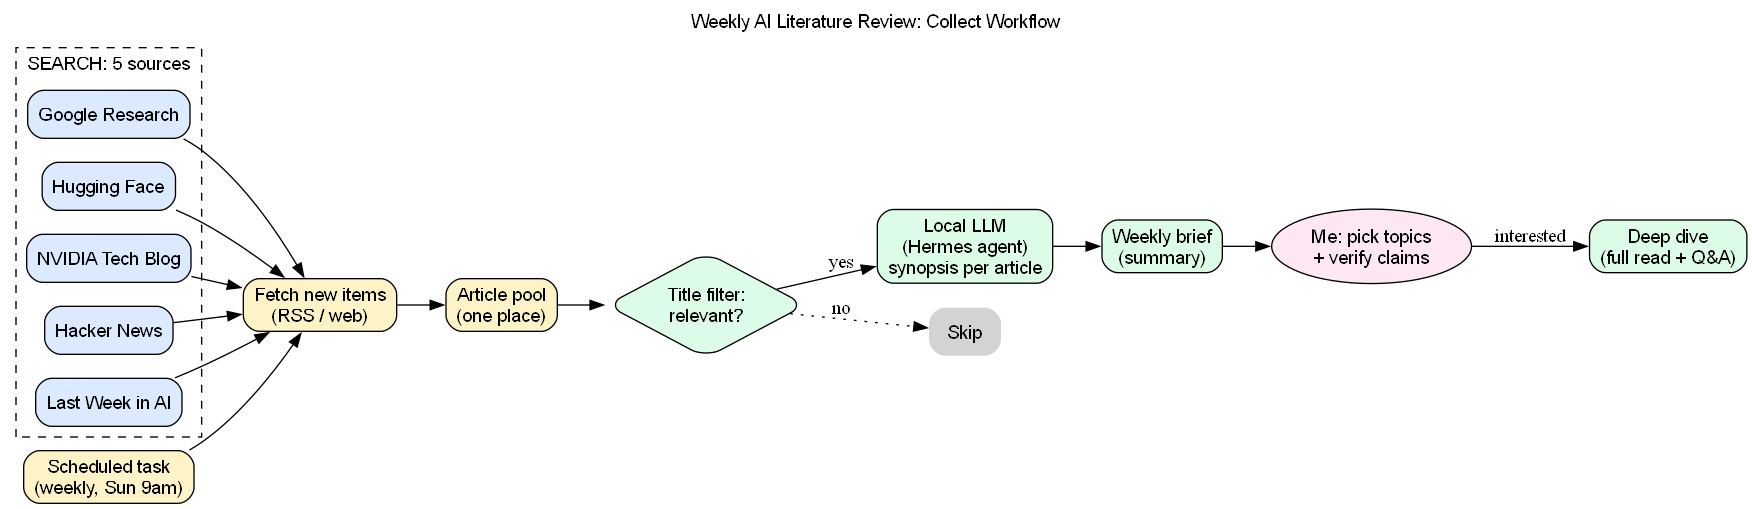

In [1]:
from graphviz import Digraph
from IPython.display import Image


g = Digraph("collect_workflow", format="png")
g.attr(rankdir="LR", fontname="Helvetica", labelloc="t",
       label="Weekly AI Literature Review: Collect Workflow")
g.attr("node", shape="box", style="rounded,filled", fontname="Helvetica")

# SEARCH: the 5 sources
with g.subgraph(name="cluster_search") as s:
    s.attr(label="SEARCH: 5 sources", style="dashed")
    for n in ["Google Research", "Hugging Face", "NVIDIA Tech Blog",
              "Hacker News", "Last Week in AI"]:
        s.node(n, fillcolor="#dbeafe")

# COLLECT: scheduled run
g.node("sched", "Scheduled task\n(weekly, Sun 9am)", fillcolor="#fef3c7")
g.node("fetch", "Fetch new items\n(RSS / web)", fillcolor="#fef3c7")
g.node("store", "Article pool\n(one place)", fillcolor="#fef3c7")

# PROCESS: local LLM
g.node("title", "Title filter:\nrelevant?", shape="diamond", fillcolor="#dcfce7")
g.node("llm", "Local LLM\n(Hermes agent)\nsynopsis per article", fillcolor="#dcfce7")
g.node("brief", "Weekly brief\n(summary)", fillcolor="#dcfce7")
g.node("me", "Me: pick topics\n+ verify claims", shape="ellipse", fillcolor="#fce7f3")
g.node("deep", "Deep dive\n(full read + Q&A)", fillcolor="#dcfce7")

for n in ["Google Research", "Hugging Face", "NVIDIA Tech Blog",
          "Hacker News", "Last Week in AI"]:
    g.edge(n, "fetch")
g.edge("sched", "fetch")
g.edge("fetch", "store")
g.edge("store", "title")
g.edge("title", "llm", label="yes")
g.node("skip", "Skip", shape="plaintext")
g.edge("title", "skip", label="no", style="dotted")
g.edge("llm", "brief")
g.edge("brief", "me")
g.edge("me", "deep", label="interested")

g.render("q1b_collect_workflow", cleanup=True)
Image("q1b_collect_workflow.png")